# 08 · 现有模型在真实手写上的表现

**目的。**notebook 07 建好了真实的测试集。这一本回答：**游戏现在用的模型，在真实书写者身上到底表现如何？**到目前为止，所有数字都来自合成数据（上线的 CNN 在合成的 `pad_tmpl` 上是 96.9%，旧 MLP 是 92.9%）。

**评估对象。**

| 模型 | 游戏里的预处理 | 来源 |
|---|---|---|
| 上线的 CNN | 面积平均缩放（`area`） | `cache/models/ship_cnn_final.keras`，由 `train_ship.py final` 训练；导出为 `digit_model/`（notebook 06 已验证 Keras 和 TF.js 的预测一致） |
| 旧 MLP | 最近邻缩放（`nn`） | `mlp_training/saved_model`，即 `mnist_tfjs_model/` 的来源 |

两个模型都按**各自在游戏里的预处理**输入，所以比较的是"游戏里的真实表现"。

**测试集**（都是按书写者划分出来的测试部分；Corr 的 `dev` 部分留给 notebook 11 调参，这里不用）：

| | 工具 | 样本 | 书写者 |
|---|---|---|---|
| Pendigits test | 触控笔 | 3,498 | 14 |
| Corr test | 手指 | 14,017 | 177 |

**要回答的问题。**

1. 两个模型在每种工具上的准确率是多少？
2. **每个数字**的准确率，以及每个数字最常被读成什么。
3. 不同书写者之间差别有多大？
4. 模型的置信度可靠吗（校准）？
5. 在游戏规则下（屏幕上有 2–3 个答案），接受率和"打错妖怪率"是多少？
6. notebook 07 里离 MNIST 最远的数字，是不是真的错得最多？

In [1]:
import json, pickle, sys
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

sys.path.insert(0, '.')
import ship, evaluate

REAL = Path('cache/real'); RESULTS = Path('results')
SEED = 8
plt.rcParams['figure.dpi'] = 110

d = np.load(REAL / 'real_digits.npz')
meta = pd.DataFrame({k: d[k] for k in ['source', 'device', 'writer', 'split', 'finger']})
meta['label'] = d['y']
with open(REAL / 'real_strokes.pkl', 'rb') as f:
    strokes = pickle.load(f)

test = meta[meta.split == 'test'].copy()
print(test.groupby(['source', 'device']).agg(digits=('label', 'size'), writers=('writer', 'nunique')))

                  digits  writers
source    device                 
corr      finger   14017      177
pendigits pen       3498       14


## 1. 两个模型的输入

CNN 的输入直接用 notebook 07 保存的图（上线版流程，面积平均缩放）。MLP 在游戏里用的是最近邻缩放，所以从原始笔画按它的流程重新画一次。

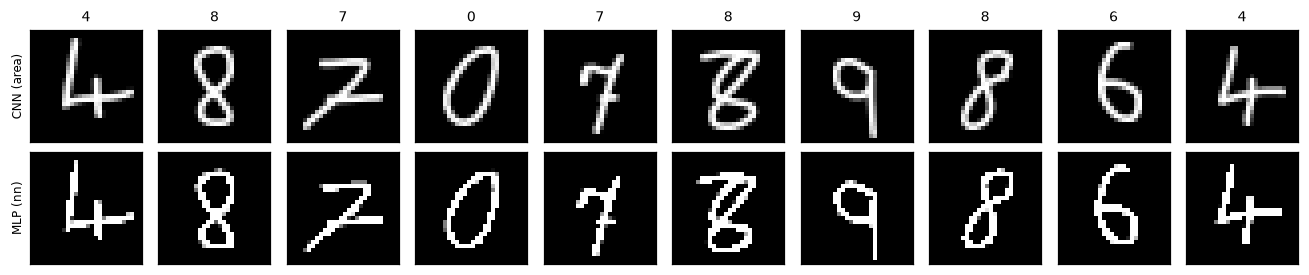

In [2]:
idx = test.index.to_numpy()
x_area = d['x'][idx].astype(np.float32) / 255

with Pool() as pool:
    x_nn = np.stack(pool.starmap(ship.to28, [(strokes[i]['strokes'], 18, 'nn') for i in idx], chunksize=200)).astype(np.float32)

fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for j, i in enumerate(np.random.default_rng(SEED).choice(len(idx), 10, replace=False)):
    axes[0, j].imshow(x_area[i], cmap='gray'); axes[1, j].imshow(x_nn[i], cmap='gray')
    axes[0, j].set_title(str(test.label.iloc[i]), fontsize=9)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel('CNN (area)', fontsize=8); axes[1, 0].set_ylabel('MLP (nn)', fontsize=8)
plt.tight_layout(); plt.show()

In [3]:
cnn = keras.models.load_model('cache/models/ship_cnn_final.keras')
p_cnn = cnn.predict(x_area[..., None], batch_size=1024, verbose=0)

mlp = tf.saved_model.load('../mlp_baseline/saved_model').signatures['serving_default']
p_mlp = np.concatenate([mlp(keras_tensor=tf.constant(x_nn[i:i + 2048].reshape(-1, 784)))['output_0'].numpy()
                        for i in range(0, len(x_nn), 2048)])
probs = {'CNN (shipped)': p_cnn, 'MLP (old)': p_mlp}
for name, p in probs.items():
    assert np.allclose(p.sum(1), 1, atol=1e-3), name      # both models end in a softmax
y = test.label.to_numpy()

## 2. 总体准确率（按工具）

置信区间按**书写者**重抽样（cluster bootstrap，1000 次）：同一个人写的字彼此相关，如果按样本重抽样，区间会窄得不真实。

In [4]:
def writer_bootstrap(correct, writers, n=1000, seed=SEED):
    """95% interval of the accuracy, resampling whole writers."""
    df = pd.DataFrame({'c': correct, 'w': writers}).groupby('w').c.agg(['sum', 'count'])
    rng = np.random.default_rng(seed)
    picks = rng.integers(0, len(df), size=(n, len(df)))
    accs = df['sum'].to_numpy()[picks].sum(1) / df['count'].to_numpy()[picks].sum(1)
    return np.percentile(accs, [2.5, 97.5])

rows = []
for name, p in probs.items():
    correct = p.argmax(1) == y
    for dev, m in test.groupby('device').groups.items():
        k = test.index.get_indexer(m)
        lo, hi = writer_bootstrap(correct[k], test.writer.to_numpy()[k])
        rows.append({'model': name, 'device': dev, 'accuracy': correct[k].mean(), 'ci_low': lo, 'ci_high': hi, 'n': len(k)})
overall = pd.DataFrame(rows)
overall.style.format({'accuracy': '{:.2%}', 'ci_low': '{:.2%}', 'ci_high': '{:.2%}'})

,model,device,accuracy,ci_low,ci_high,n
0,CNN (shipped),finger,98.36%,98.02%,98.71%,14017
1,CNN (shipped),pen,96.26%,93.26%,98.46%,3498
2,MLP (old),finger,95.54%,94.91%,96.18%,14017
3,MLP (old),pen,88.79%,85.28%,91.74%,3498


作为对照，notebook 06 在**合成**的 `pad_tmpl` 上的结果是：CNN 96.9%，MLP 92.9%。

## 3. 每个数字的准确率

In [5]:
per_digit = {}
for name, p in probs.items():
    pred = p.argmax(1)
    per_digit[name] = pd.DataFrame({dev: [(pred[k][y[k] == c] == c).mean() for c in range(10)]
                                    for dev, k in ((dev, test.index.get_indexer(m)) for dev, m in test.groupby('device').groups.items())})
table = pd.concat(per_digit, axis=1) * 100
table.index.name = 'digit'
table.round(1)

CNN (shipped)        MLP (old)      
             finger    pen    finger   pen
digit                                     
0              99.8  100.0      99.4  99.7
1              94.3   92.0      95.5  85.2
2              98.8   99.5      96.7  97.0
3              98.6   96.4      96.5  92.9
4              97.6   92.3      85.7  86.0
5              99.3   99.1      97.1  98.5
6              99.3   97.0      96.3  95.2
7              99.2   92.0      97.3  77.2
8              97.6  100.0      93.3  96.4
9              99.1   94.6      97.6  59.8

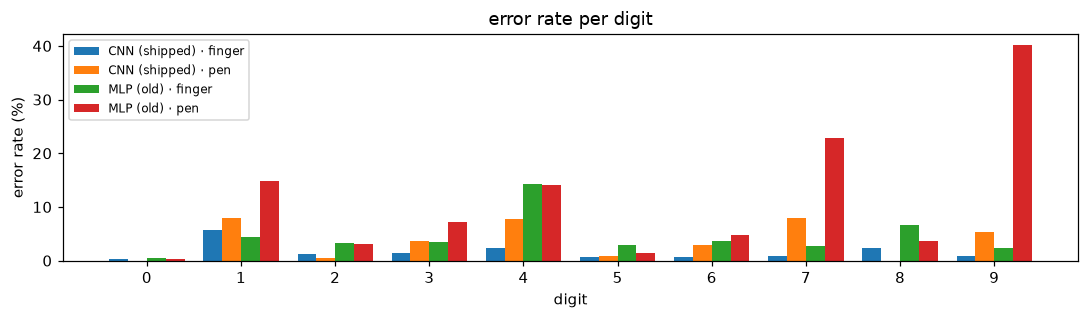

In [6]:
fig, ax = plt.subplots(figsize=(10, 3))
w = 0.2
for j, (col, vals) in enumerate(table.items()):
    ax.bar(np.arange(10) + (j - 1.5) * w, 100 - vals, w, label=' · '.join(col))
ax.set_xticks(range(10)); ax.set_xlabel('digit'); ax.set_ylabel('error rate (%)'); ax.legend(fontsize=8)
ax.set_title('error rate per digit')
plt.tight_layout(); plt.show()

## 4. 混淆矩阵：每个数字被读成了什么

每一行是真实的数字，每一格是"被读成这一列"的比例（%）。

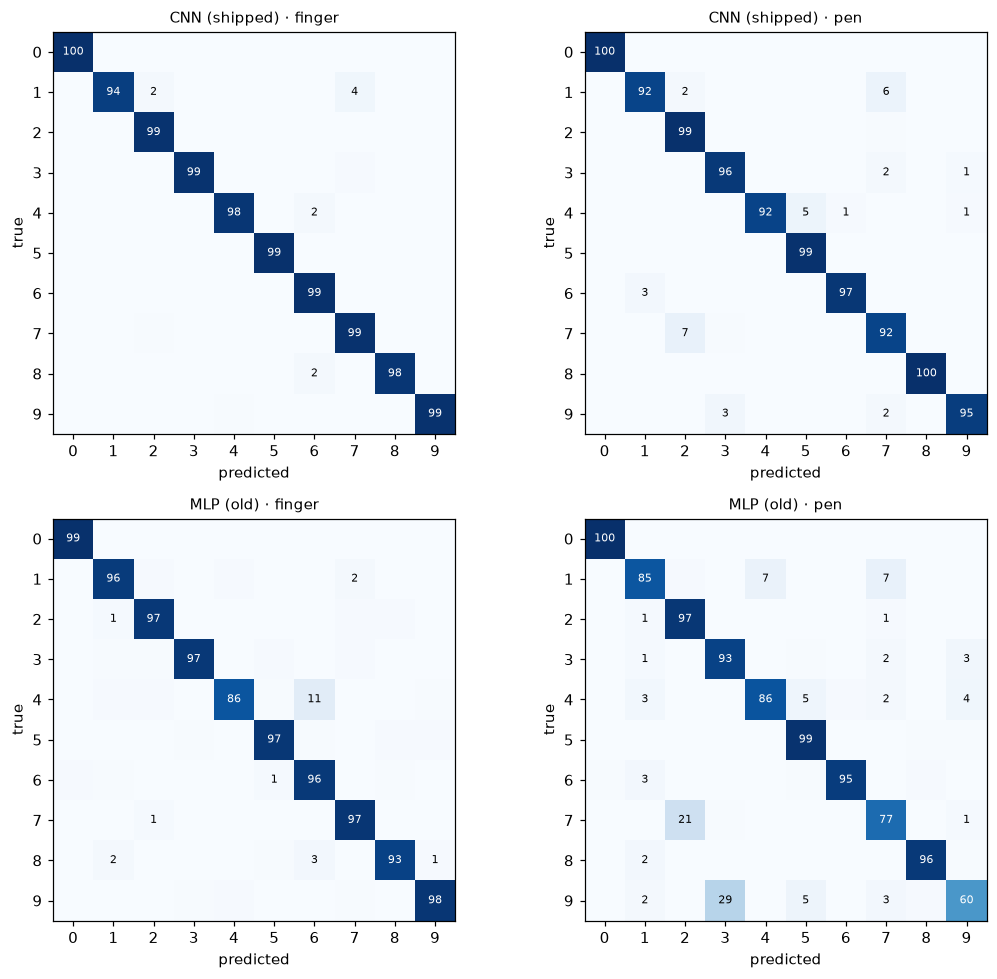

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for r, (name, p) in enumerate(probs.items()):
    for c, (dev, m) in enumerate(test.groupby('device').groups.items()):
        k = test.index.get_indexer(m)
        evaluate.plot_confusion(y[k], p[k].argmax(1), f'{name} · {dev}', ax=axes[r, c])
plt.tight_layout(); plt.show()

In [8]:
def top_confusions(true, pred, n=10):
    err = pd.Series(list(zip(true[true != pred], pred[true != pred]))).value_counts()
    totals = pd.Series(true).value_counts()
    return pd.DataFrame([{'true → read as': f'{a} → {b}', 'count': c, '% of that digit': 100 * c / totals[a]}
                         for (a, b), c in err.head(n).items()])

for dev, m in test.groupby('device').groups.items():
    k = test.index.get_indexer(m)
    print(f'CNN (shipped) · {dev}: most common errors')
    print(top_confusions(y[k], p_cnn[k].argmax(1)).round(1).to_string(index=False)); print()

CNN (shipped) · finger: most common errors
true → read as  count  % of that digit
         1 → 7     54              3.9
         4 → 6     27              1.9
         1 → 2     25              1.8
         8 → 6     24              1.7
         3 → 7     14              1.0
         7 → 2      8              0.6
         9 → 4      6              0.4
         2 → 7      5              0.4
         9 → 7      5              0.4
         5 → 3      4              0.3

CNN (shipped) · pen: most common errors
true → read as  count  % of that digit
         7 → 2     27              7.4
         1 → 7     22              6.0
         4 → 5     19              5.2
         9 → 3     11              3.3
         6 → 1      9              2.7
         3 → 7      6              1.8
         1 → 2      6              1.6
         9 → 7      6              1.8
         3 → 9      5              1.5
         4 → 6      4              1.1



## 5. 错误长什么样

每个数字挑几个上线 CNN 读错的例子（图上是模型看到的 28×28 输入；标题是"真实 → 读成"和置信度）。

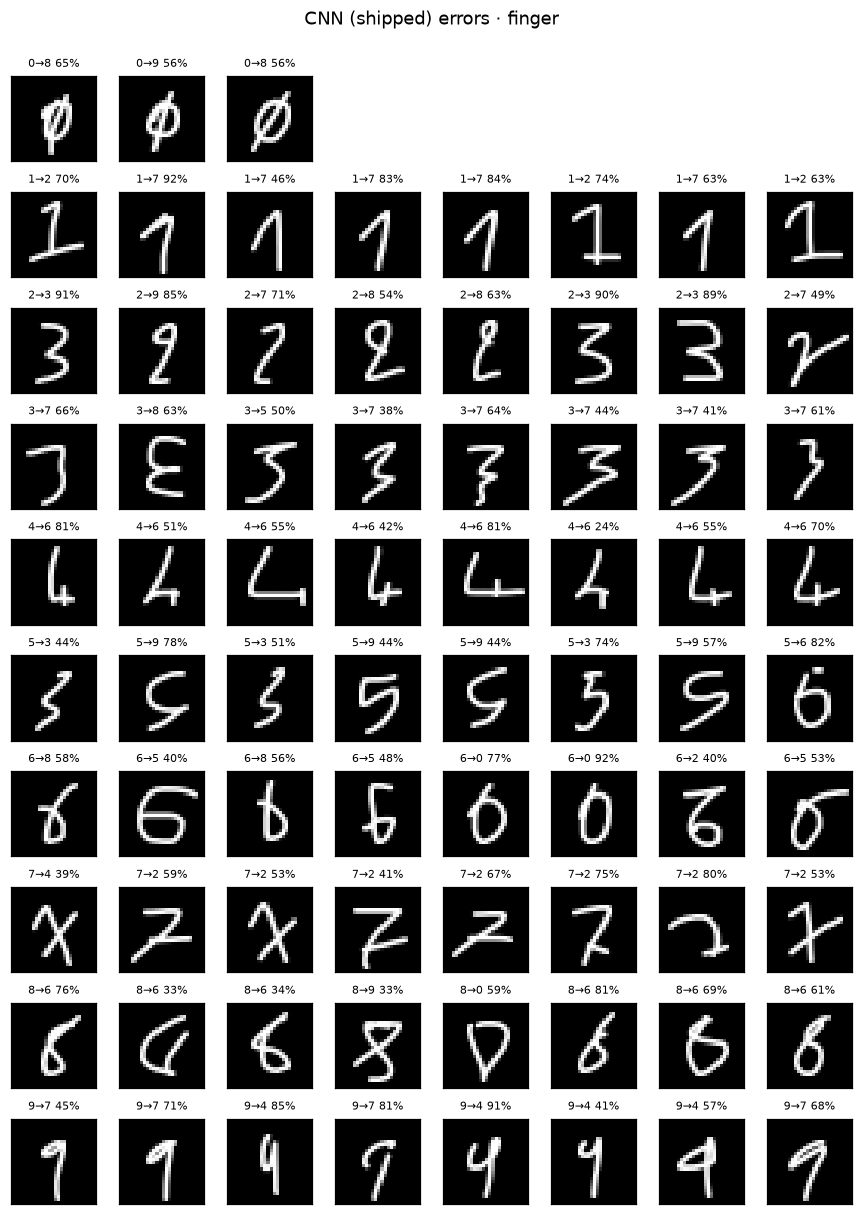

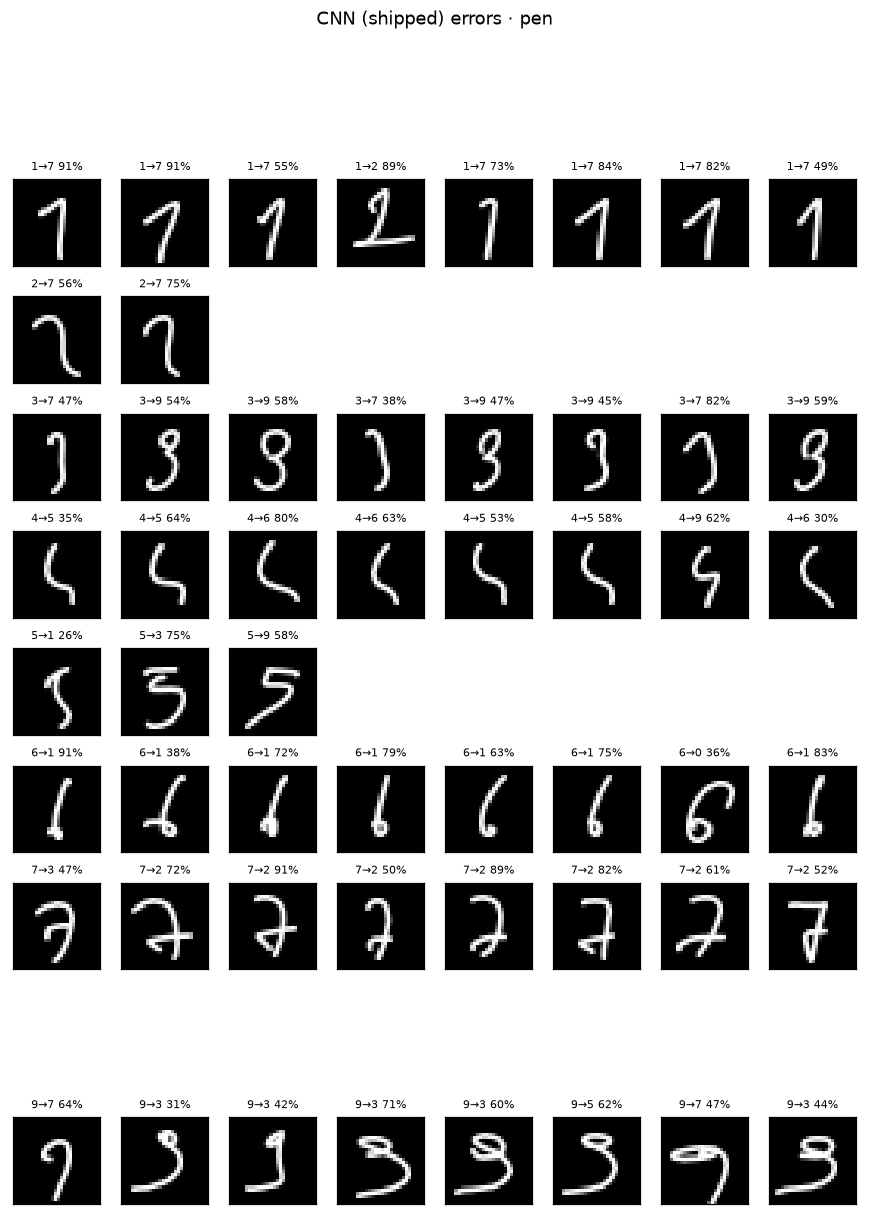

In [9]:
pred_cnn = p_cnn.argmax(1)
for dev, m in test.groupby('device').groups.items():
    k = test.index.get_indexer(m)
    fig, axes = plt.subplots(10, 8, figsize=(8, 11))
    for c in range(10):
        wrong = k[(y[k] == c) & (pred_cnn[k] != c)]
        pick = np.random.default_rng(SEED + c).choice(wrong, size=min(8, len(wrong)), replace=False) if len(wrong) else []
        for j in range(8):
            ax = axes[c, j]; ax.set_xticks([]); ax.set_yticks([])
            if j < len(pick):
                i = pick[j]
                ax.imshow(x_area[i], cmap='gray')
                ax.set_title(f'{c}→{pred_cnn[i]} {p_cnn[i].max():.0%}', fontsize=7)
            else:
                ax.axis('off')
    fig.suptitle(f'CNN (shipped) errors · {dev}', y=1.0)
    plt.tight_layout(); plt.show()

## 6. 书写者之间的差别

每个书写者单独算一个准确率，看分布：大多数人都还行、少数人特别差，还是所有人都一般？

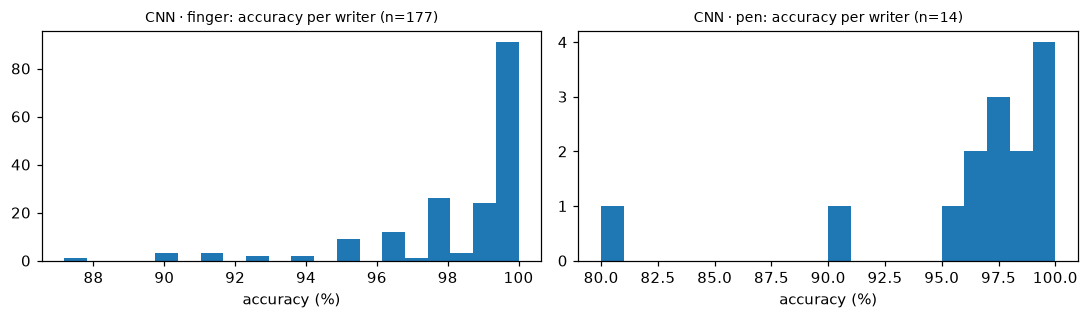

        count   mean    std    min    10%    25%    50%    75%  max
device                                                             
finger  177.0  0.984  0.024  0.872  0.950  0.975  1.000  1.000  1.0
pen      14.0  0.963  0.054  0.800  0.917  0.964  0.974  0.997  1.0


In [10]:
per_writer = test.assign(ok=(pred_cnn == y)).groupby(['device', 'writer']).ok.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (dev, g) in zip(axes, per_writer.groupby('device')):
    ax.hist(g.ok * 100, bins=20, color='tab:blue')
    ax.set_title(f'CNN · {dev}: accuracy per writer (n={len(g)})', fontsize=9); ax.set_xlabel('accuracy (%)')
plt.tight_layout(); plt.show()
print(per_writer.groupby('device').ok.describe(percentiles=[0.1, 0.25, 0.5, 0.75]).round(3))

In [11]:
# Corr also records which finger wrote the digit
corr_k = (test.device == 'finger').to_numpy()
by_finger = test[corr_k].assign(ok=(pred_cnn == y)[corr_k]).groupby('finger').ok.agg(['mean', 'size'])
by_finger

,mean,size
finger,,
index,0.985160,7008
thumb,0.982023,7009


## 7. 置信度是否可靠（校准）

游戏的 `decide()` 直接用模型给出的概率做判断，所以概率要"说话算数"：模型说 90% 有把握时，应该大约 90% 是对的。

- **可靠性图**：把预测按置信度分组，比较每组的平均置信度和实际准确率；完全校准的模型落在对角线上。
- **ECE**（expected calibration error）：各组"置信度 − 准确率"的加权平均差距，越小越好。
- 另外统计"**自信地读错**"的比例：读错了、置信度却超过 90%。这类错误 `decide()` 最难救回来。

注意：上线的 CNN 训练时用了 label smoothing（0.1），它会把最高置信度压到 0.9 左右，这会影响下面的数字（notebook 06 已提到）。

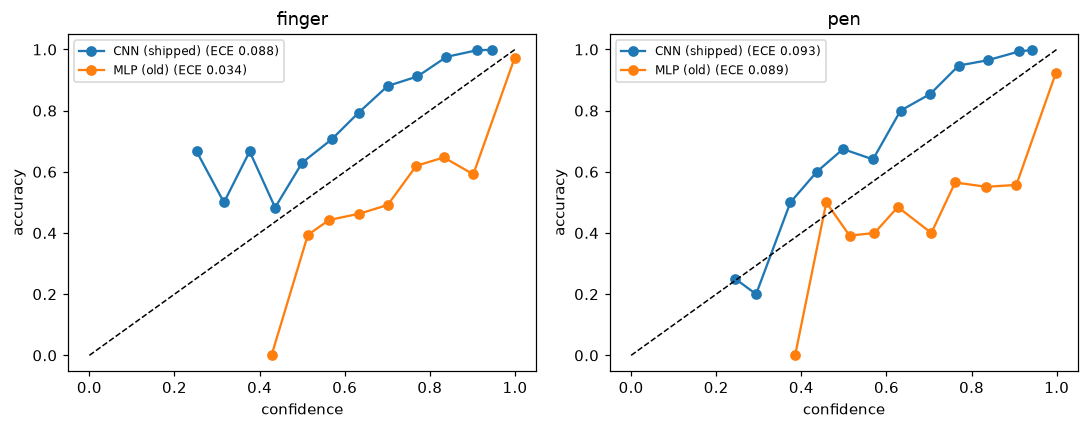

,model,device,ECE,confident errors (wrong and >90%) %
0,CNN (shipped),finger,0.088,0.107
1,MLP (old),finger,0.034,2.968
2,CNN (shipped),pen,0.093,0.257
3,MLP (old),pen,0.089,7.576


In [12]:
def calibration(p, y, bins=15):
    conf, ok = p.max(1), p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            rows.append((conf[m].mean(), ok[m].mean(), m.sum()))
    rows = np.array(rows)
    ece = (np.abs(rows[:, 0] - rows[:, 1]) * rows[:, 2]).sum() / len(y)
    return rows, ece

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cal_rows = []
for ax, (dev, m) in zip(axes, test.groupby('device').groups.items()):
    k = test.index.get_indexer(m)
    for name, p in probs.items():
        rows, ece = calibration(p[k], y[k])
        ax.plot(rows[:, 0], rows[:, 1], 'o-', label=f'{name} (ECE {ece:.3f})')
        wrong = p[k].argmax(1) != y[k]
        cal_rows.append({'model': name, 'device': dev, 'ECE': ece,
                         'confident errors (wrong and >90%) %': 100 * (wrong & (p[k].max(1) > 0.9)).mean()})
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.set_title(dev); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
cal = pd.DataFrame(cal_rows)
cal.round(3)

## 8. 在游戏规则下的表现

游戏不是十选一：屏幕上通常只有两三个答案，`decide()` 会结合它们判断（Python 版本在 `evaluate.decide`，和 `js/game/handwriting.js` 完全一致）。对每个样本，随机抽另外 1 个或 2 个数字和真实答案一起作为"屏幕上的答案"，然后统计：

- **接受**：判为命中，而且命中的是正确答案。
- **打错妖怪**：判为命中，但命中的是屏幕上**另一个**答案。体验最差的错误。
- **其他**：判为"没看清"或"写错了"，玩家需要重写或会被判错。

In [13]:
game_rows = []
for name, p in probs.items():
    for dev, m in test.groupby('device').groups.items():
        k = test.index.get_indexer(m)
        for n_ans in (2, 3):
            acc, wrong, other = evaluate.game_hit_rate(p[k], y[k], n_answers=n_ans, seed=SEED)
            game_rows.append({'model': name, 'device': dev, 'answers on screen': n_ans,
                              'accepted %': 100 * acc, 'wrong yokai %': 100 * wrong, 'rewrite / miss %': 100 * other})
game = pd.DataFrame(game_rows)
game.round(2)

,model,device,answers on screen,accepted %,wrong yokai %,rewrite / miss %
0,CNN (shipped),finger,2,98.96,0.22,0.82
1,CNN (shipped),finger,3,98.83,0.42,0.75
2,CNN (shipped),pen,2,97.26,0.31,2.43
3,CNN (shipped),pen,3,97.06,0.94,2.00
4,MLP (old),finger,2,96.10,0.60,3.30
5,MLP (old),finger,3,96.01,1.05,2.94
6,MLP (old),pen,2,90.02,1.32,8.66
7,MLP (old),pen,3,89.94,2.37,7.69


## 9. 离 MNIST 越远的数字，错得越多吗？

notebook 07 第 7 节给每个数字算了一个"写法离 MNIST 有多远"的分数（TVD）。如果写法差距是错误的主要来源，这个分数应该和每个数字的错误率正相关。用 Spearman 等级相关来检验（只有 10 个点，结论要谨慎）。

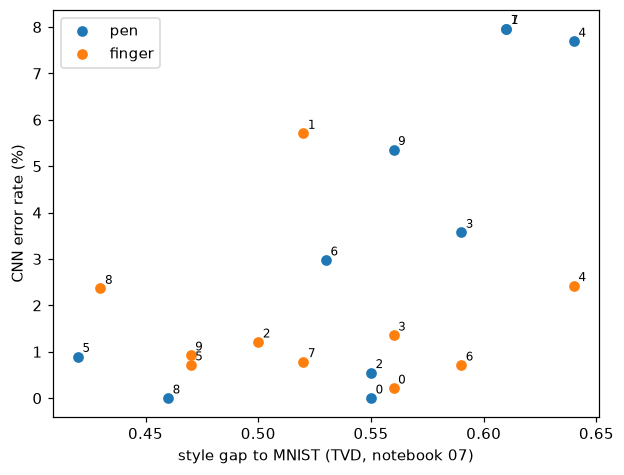

,device,spearman rho,p-value
0,pen,0.801,0.005
1,finger,-0.067,0.853


In [14]:
from scipy.stats import spearmanr
gap = json.loads((RESULTS / '07_datasets.json').read_text())['style_gap_tvd']
rows = []
for dev, col in (('pen', 'pen vs MNIST'), ('finger', 'finger vs MNIST')):
    err = 100 - table[('CNN (shipped)', dev)]
    g = np.array([gap[str(c)][col] for c in range(10)])
    rho, pv = spearmanr(g, err)
    rows.append({'device': dev, 'spearman rho': rho, 'p-value': pv})
    plt.scatter(g, err, label=dev)
    for c in range(10):
        plt.annotate(str(c), (g[c], err[c]), fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel('style gap to MNIST (TVD, notebook 07)'); plt.ylabel('CNN error rate (%)'); plt.legend(); plt.show()
pd.DataFrame(rows).round(3)

## 10. 保存

In [15]:
out = {
    'overall': overall.to_dict(orient='records'),
    'per_digit_accuracy_percent': {f'{a} | {b}': table[(a, b)].round(2).tolist() for a, b in table.columns},
    'calibration': cal.to_dict(orient='records'),
    'game': game.to_dict(orient='records'),
    'per_writer_cnn': per_writer.groupby('device').ok.describe().round(4).to_dict(orient='index'),
    'seed': SEED,
}
(RESULTS / '08_baseline.json').write_text(json.dumps(out, indent=2, default=float))
print('saved results/08_baseline.json')

saved results/08_baseline.json


## 11. 结论与下一步

**1. 真实数据上的总体准确率（95% 置信区间按书写者重抽样）**

| 模型 | 手指（Corr，177 人） | 触控笔（Pendigits，14 人） |
|---|---|---|
| 上线的 CNN | **98.36%**（98.02–98.71） | **96.26%**（93.26–98.46） |
| 旧 MLP | 95.54%（94.91–96.18） | 88.79%（85.28–91.74） |

- 换成 CNN 的收益在真实数据上得到了确认：手指上的错误率从 4.5% 降到 1.6%，触控笔上从 11.2% 降到 3.7%，都降了约三分之二。
- 手指上的结果比合成测试集 `pad_tmpl`（96.9%）还好，说明合成数据比真实的手指书写更难；触控笔则和合成数据相当。
- 触控笔只有 14 位测试书写者，区间很宽（93–98%），这个数字只能作为参考。

**2. 每个数字（上线的 CNN）**

- 手指：最弱的是 **1**（94.3%），其次是 4 和 8（97.6%），其余都在 98.6% 以上。
- 触控笔：最弱的是 **1、7**（92.0%）、**4**（92.3%）和 **9**（94.6%）。
- 最常见的错误：
  - 手指：1→7（3.9%）、4→6（1.9%）、1→2（1.8%）、8→6（1.7%）、3→7（1.0%）。
  - 触控笔：7→2（7.4%）、1→7（6.0%）、4→5（5.2%）、9→3（3.3%）、6→1（2.7%）。
- 从错误样例（第 5 节）看，错误主要来自**MNIST 里少见的写法**：
  - **带横的 7** 被读成 2。
  - **一笔写成、顶端开口的 4** 被读成 5 或 6。
  - **竖直尾巴的 9** 被读成 7 或 4。
  - **圈很小、几乎是一竖的 6** 被读成 1。
  - **一个圈写成的 8** 被读成 6。
  - **带斜杠的 0（ø）** 被读成 8。
- 有一部分错误样例在人眼看来也很模糊，有的看起来像标错了（比如被标成 2、看起来却像 3 的字）。所以真实数据上的准确率上限本身就低于 100%。

**3. 书写者之间的差别**

手指数据里，一半的书写者是 100%，10% 分位数是 95%，最差的一位是 87.2%。错误集中在少数人和少数写法上，而不是所有人都差一点。食指和拇指几乎没有差别（98.5% 对 98.2%）。

**4. 置信度：CNN 偏保守，MLP 偏自信**

- 上线的 CNN 在两种工具上都**低估了自己**（可靠性曲线在对角线上方，ECE ≈ 0.09），这是 label smoothing 的副作用。好处是"读错而且置信度超过 90%"几乎不存在（手指 0.11%，触控笔 0.26%）。
- 旧 MLP 则相反，读错时也常常很自信（"自信地读错"占 3.0% 和 7.6%）。
- CNN 的概率偏低，会让 `decide()` 把一些本来读对的字判成"没看清"。notebook 11 可以用温度缩放把概率校准好，再重新确定 `decide()` 的阈值。

**5. 游戏规则下（上线的 CNN）**

| | 屏幕上 2 个答案 | 屏幕上 3 个答案 |
|---|---|---|
| 手指：接受 / 打错妖怪 / 需重写 | 98.96% / 0.22% / 0.82% | 98.83% / 0.42% / 0.75% |
| 触控笔：接受 / 打错妖怪 / 需重写 | 97.26% / 0.31% / 2.43% | 97.06% / 0.94% / 2.00% |

"打错妖怪"在 1% 以下；剩下的损失主要是"需要重写"，这部分和上面说的置信度偏低有关。

**6. 离 MNIST 越远的数字错得越多吗？**

- 触控笔上是的：写法差距（notebook 07 的 TVD）和错误率的等级相关系数为 0.80（p = 0.005）。
- 手指上看不出关系（−0.07）。手指上的错误更多来自个别人的个别写法，而不是整体的写法偏移。
- 只有 10 个点，这个结论要谨慎看待。

**下一步：notebook 09。**把真实的触控笔数据（Pendigits 训练部分）加入训练，重点覆盖上面这些 MNIST 里少见的写法；同时试一下对"倾斜、笔宽"这类所有数字共有的差异做数据增强。用 Pendigits 的验证集和 Corr 的 `dev` 挑方案，最后在两个测试集上报告。
